In [1]:
import sys
sys.path.append("..")
from pathlib import Path
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.evaluate import add_onset, bootstrap_metrics, threshold_table, alert_metrics, calibration

THRESHOLD = 0.05      # chosen on Hospital A validation; unchanged
ROOT = Path("..").resolve()
PRED = ROOT / "data" / "predictions"
FIG_DIR = ROOT / "reports" / "figures" / "external"
FIG_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(ROOT / "data" / "sepsis.duckdb"), read_only=True)
cohort = con.execute("""
    SELECT patient_id, split, septic, onset_iculos, first_iculos, age, gender
    FROM cohort WHERE split IN ('test', 'external')
""").df()
con.close()

def load(name, split):
    return add_onset(pd.read_parquet(PRED / f"{name}_{split}.parquet"),
                     cohort[cohort["split"] == split])

test_main = load("lgbm", "test")             # Hospital A test, for side-by-side comparison
b_main = load("lgbm", "external")
b_no = load("lgbm-ordering", "external")
cohort_b = cohort[cohort["split"] == "external"]
print(len(b_main), b_main["patient_id"].nunique(), int(cohort_b["septic"].sum()))
# expect 760117 rows, 19777 patients, 919 septic

760117 19777 919


In [2]:
rows = []
for label, d in [("A test, main", test_main), ("B, main", b_main), ("B, without ordering", b_no)]:
    for scope, sub in [("all hours", d), ("pre-onset hours", d[d["pre_onset"]])]:
        m = bootstrap_metrics(sub["y"], sub["p"], sub["patient_id"], n_boot=200)
        rows.append({"model": label, "scope": scope, "random_auprc": round(sub["y"].mean(), 3),
                     **{k: f"{v[0]:.3f} ({v[1]:.3f}–{v[2]:.3f})" for k, v in m.items()}})
pd.DataFrame(rows)

,model,scope,random_auprc,auroc,auprc
0,"A test, main",all hours,0.020,0.805 (0.782–0.830),0.091 (0.075–0.108)
1,"A test, main",pre-onset hours,0.012,0.793 (0.767–0.817),0.054 (0.044–0.066)
2,"B, main",all hours,0.012,0.768 (0.753–0.781),0.052 (0.046–0.060)
3,"B, main",pre-onset hours,0.007,0.749 (0.734–0.762),0.028 (0.025–0.032)
4,"B, without ordering",all hours,0.012,0.771 (0.757–0.784),0.048 (0.042–0.056)
5,"B, without ordering",pre-onset hours,0.007,0.751 (0.736–0.765),0.026 (0.023–0.031)


In [3]:
n_sep_b = int(cohort_b["septic"].sum())
ops_b = threshold_table(b_main, [0.03, THRESHOLD, 0.10])
ops_b["septic_caught_early"] = (ops_b["early_sensitivity"] * n_sep_b).round().astype(int).astype(str) + f" / {n_sep_b}"
display(ops_b.round(3))

ops_b_no = threshold_table(b_no, [THRESHOLD])
display(ops_b_no.round(3))

,threshold,early_sensitivity,median_lead_h,alerts_per_100_patient_days,alert_ppv,nonseptic_patients_alerted,septic_caught_early
0,0.03,0.437,7.0,29.190,0.088,0.150,402 / 919
1,0.05,0.248,6.0,12.690,0.111,0.068,228 / 919
2,0.10,0.087,5.0,3.161,0.155,0.017,80 / 919


,threshold,early_sensitivity,median_lead_h,alerts_per_100_patient_days,alert_ppv,nonseptic_patients_alerted
0,0.05,0.248,7.0,14.631,0.104,0.068


Hospital A test: mean predicted 0.0165 vs actual positive rate 0.0196
Hospital B: mean predicted 0.0087 vs actual positive rate 0.0117


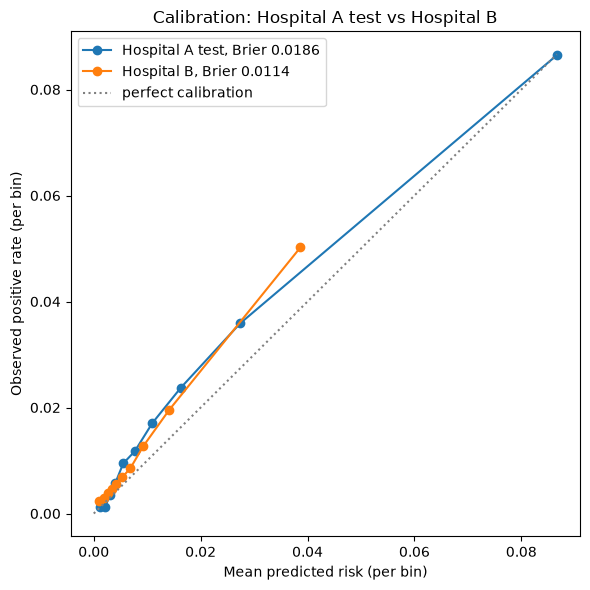

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
top = 0
for label, d in [("Hospital A test", test_main), ("Hospital B", b_main)]:
    cal, brier = calibration(d["y"], d["p"])
    ax.plot(cal["mean_predicted"], cal["observed_rate"], marker="o", label=f"{label}, Brier {brier:.4f}")
    top = max(top, cal["mean_predicted"].max(), cal["observed_rate"].max())
    print(f"{label}: mean predicted {d['p'].mean():.4f} vs actual positive rate {d['y'].mean():.4f}")
ax.plot([0, top], [0, top], linestyle=":", color="gray", label="perfect calibration")
ax.set_xlabel("Mean predicted risk (per bin)")
ax.set_ylabel("Observed positive rate (per bin)")
ax.set_title("Calibration: Hospital A test vs Hospital B")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "calibration_A_vs_B.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
pts_b = cohort_b.assign(
    age_group=pd.cut(cohort_b["age"], [0, 50, 65, 80, 200], right=False,
                     labels=["<50", "50–64", "65–79", "80+"]),
    sex=cohort_b["gender"].map({0: "female", 1: "male"}),
)
db = b_main.merge(pts_b[["patient_id", "age_group", "sex"]], on="patient_id")

def subgroup_rows(d, col):
    rows = []
    for g, sub in d.groupby(col, observed=True):
        m = bootstrap_metrics(sub["y"], sub["p"], sub["patient_id"], n_boot=200)
        a = alert_metrics(sub, THRESHOLD)
        rows.append({
            "group": f"{col}: {g}",
            "patients": sub["patient_id"].nunique(),
            "septic": int(sub.drop_duplicates("patient_id")["septic"].sum()),
            "auroc (95% CI)": f"{m['auroc'][0]:.3f} ({m['auroc'][1]:.3f}–{m['auroc'][2]:.3f})",
            "early_sensitivity": round(a["early_sensitivity"], 3),
            "nonseptic_alerted": round(a["nonseptic_patients_alerted"], 3),
            "alert_ppv": round(a["alert_ppv"], 3),
        })
    return rows

pd.DataFrame(subgroup_rows(db, "age_group") + subgroup_rows(db, "sex"))

,group,patients,septic,auroc (95% CI),early_sensitivity,nonseptic_alerted,alert_ppv
0,age_group: <50,4757,215,0.729 (0.700–0.760),0.214,0.063,0.098
1,age_group: 50–64,6200,273,0.780 (0.759–0.810),0.289,0.066,0.109
2,age_group: 65–79,6525,329,0.772 (0.752–0.792),0.237,0.079,0.111
3,age_group: 80+,2295,102,0.810 (0.777–0.839),0.245,0.050,0.158
4,sex: female,9171,398,0.779 (0.762–0.800),0.256,0.056,0.128
5,sex: male,10606,521,0.759 (0.740–0.778),0.242,0.078,0.100


In [6]:
sep_b = cohort_b[cohort_b["septic"] == 1].assign(
    history_before_onset=lambda x: x["onset_iculos"] - x["first_iculos"])
sep_b["history_group"] = np.where(sep_b["history_before_onset"] <= 24,
                                  "onset within 24 h of record start", "onset after 24 h")
rows = []
for g, grp in sep_b.groupby("history_group"):
    a = alert_metrics(b_main[b_main["patient_id"].isin(grp["patient_id"])], THRESHOLD)
    rows.append({"group": g, "septic_patients": len(grp),
                 "early_sensitivity": round(a["early_sensitivity"], 3),
                 "median_lead_h": a["median_lead_h"]})
pd.DataFrame(rows)

,group,septic_patients,early_sensitivity,median_lead_h
0,onset after 24 h,651,0.303,6.0
1,onset within 24 h of record start,268,0.116,5.0


## Findings (Part A: Hospital B, frozen model and threshold)
- Discrimination: AUROC 0.768 (0.753–0.781) vs 0.805 at A test; AUPRC 0.052 vs random 0.012 (4.4×; A: 4.6×). Pre-onset: AUROC 0.749, AUPRC 0.028 vs random 0.007 (4.0×). Ranking mostly transfers; real but moderate AUROC drop.
- Ordering features neutral at B (AUROC 0.768 vs 0.771 without; AUPRC 0.052 vs 0.048)
- Threshold 0.05 does not transfer: 25% warned early (228/919) vs 49% at A; 12.7 alerts / 100 patient-days vs 39; PPV 11.1%; 7% of non-septic alerted. At 0.03, B resembles A at 0.05 (44% warned, 29 alerts).
- Calibration: underestimates at B (mean predicted 0.0087 vs observed 0.0117), opposite to the expected overestimation. Hypothesis: strong features rely on measurements rarely made at B (FiO2 98% missing, blood gases), lowering scores. Test with drift table.
- Subgroups: sex gap from A did not replicate (B: female 26% vs male 24% early sensitivity; AUROC 0.779 vs 0.759); age pattern inconsistent across hospitals. No consistent subgroup disparity; A's gaps likely chance.
- Early-stay limitation replicates: onset after 24 h 30% warned vs within 24 h 12% (A: 60% vs 27%).

In [7]:
TOP = ["FiO2_hrs_since", "hours_available24", "BUN_last", "Resp_mean24", "Lactate_last",
       "Calcium_last", "HospAdmTime", "Unit1", "PTT_last", "Temp_max6",
       "warning_criteria_count", "Temp_last", "Phosphate_last", "WBC_last", "Age"]

con = duckdb.connect(str(ROOT / "data" / "sepsis.duckdb"), read_only=True)
a_feat = con.execute(f"SELECT {', '.join(TOP)} FROM features WHERE split = 'train'").df()
b_feat = con.execute(f"SELECT {', '.join(TOP)} FROM features WHERE split = 'external'").df()
con.close()
print(len(a_feat), len(b_feat))   # expect 550591 and 760117

550591 760117


In [8]:
def psi(a, b, bins=10):
    """Population Stability Index between reference sample a and new sample b.
    Missing values get their own bin, since missingness itself can shift."""
    a_obs, b_obs = a.dropna(), b.dropna()
    if a_obs.nunique() <= 10:                                   # categorical / few values
        cats = sorted(set(a_obs.unique()) | set(b_obs.unique()))
        pa = np.array([(a == c).mean() for c in cats])
        pb = np.array([(b == c).mean() for c in cats])
    else:                                                       # continuous: bins from A's quantiles
        edges = np.unique(np.quantile(a_obs, np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        pa = np.histogram(a_obs, edges)[0] / len(a)
        pb = np.histogram(b_obs, edges)[0] / len(b)
    pa = np.clip(np.append(pa, a.isna().mean()), 1e-6, None)
    pb = np.clip(np.append(pb, b.isna().mean()), 1e-6, None)
    return float(np.sum((pb - pa) * np.log(pb / pa)))

rows = []
for f in TOP:
    rows.append({"feature": f,
                 "missing_A": round(a_feat[f].isna().mean(), 3),
                 "missing_B": round(b_feat[f].isna().mean(), 3),
                 "median_A": a_feat[f].median(),
                 "median_B": b_feat[f].median(),
                 "PSI": round(psi(a_feat[f], b_feat[f]), 3)})
drift = pd.DataFrame(rows).sort_values("PSI", ascending=False)
drift

,feature,missing_A,missing_B,median_A,median_B,PSI
8,PTT_last,0.326,0.784,30.800000,31.300000,0.952
0,FiO2_hrs_since,0.420,0.710,2.000000,11.000000,0.673
6,HospAdmTime,0.000,0.000,-2.590000,-8.980000,0.648
7,Unit1,0.490,0.296,1.000000,0.000000,0.161
12,Phosphate_last,0.333,0.525,3.300000,3.300000,0.154
5,Calcium_last,0.338,0.227,8.300000,8.400000,0.113
13,WBC_last,0.181,0.269,10.900000,9.500000,0.111
11,Temp_last,0.072,0.075,36.940000,36.800000,0.108
3,Resp_mean24,0.021,0.042,17.895833,18.152174,0.088
9,Temp_max6,0.106,0.125,37.060000,36.800000,0.078


In [9]:
import mlflow, shap

RUN_ID = "8eb22f64550f4aaa813a9a521a0fc3f9"          # final model
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")
model = mlflow.lightgbm.load_model(f"runs:/{RUN_ID}/model")
feats = mlflow.artifacts.load_text(f"runs:/{RUN_ID}/features.txt").split("\n")

con = duckdb.connect(str(ROOT / "data" / "sepsis.duckdb"), read_only=True)
xa = con.execute(f"SELECT {', '.join(feats)} FROM features WHERE split = 'test'").df()
xb = con.execute(f"SELECT {', '.join(feats)} FROM features WHERE split = 'external'").df()
con.close()
xa = xa.sample(10000, random_state=0).astype("float32")
xb = xb.sample(10000, random_state=0).astype("float32")

explainer = shap.TreeExplainer(model)
mean_a = explainer(xa).values.mean(axis=0)
mean_b = explainer(xb).values.mean(axis=0)
shift = pd.Series(mean_b - mean_a, index=feats).sort_values()

print(f"Total shift in mean log-odds (B minus A): {shift.sum():.3f}")
print("\nFeatures lowering B's scores most:\n", shift.head(10).round(3))
print("\nFeatures raising B's scores most:\n", shift.tail(5).round(3))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Total shift in mean log-odds (B minus A): -0.377

Features lowering B's scores most:
 FiO2_hrs_since    -0.240
HospAdmTime       -0.072
PTT_last          -0.057
FiO2_n24          -0.042
Lactate_last      -0.031
FiO2_last         -0.029
MAP_min6          -0.023
Phosphate_last    -0.020
Temp_max6         -0.017
hrs_map_lt65_12   -0.016
dtype: float64

Features raising B's scores most:
 Calcium_change24    0.021
Hgb_last            0.021
Chloride_last       0.027
DBP_max6            0.034
Calcium_last        0.039
dtype: float64


In [10]:
ids = np.sort(cohort_b["patient_id"].unique())
rng = np.random.default_rng(42)
cal_ids = set(rng.choice(ids, size=len(ids) // 2, replace=False))

b_cal = b_main[b_main["patient_id"].isin(cal_ids)].copy()
b_eval = b_main[~b_main["patient_id"].isin(cal_ids)].copy()
for name, d in [("calibration half", b_cal), ("evaluation half", b_eval)]:
    pts = d.drop_duplicates("patient_id")
    print(f"{name}: {len(pts)} patients, {int(pts['septic'].sum())} septic, {len(d)} hours")

calibration half: 9888 patients, 438 septic, 377518 hours
evaluation half: 9889 patients, 481 septic, 382599 hours


Recalibration: slope 0.960, intercept 0.102
before recalibration: mean predicted 0.0088 vs observed 0.0121 | AUROC 0.766
after recalibration: mean predicted 0.0114 vs observed 0.0121 | AUROC 0.766


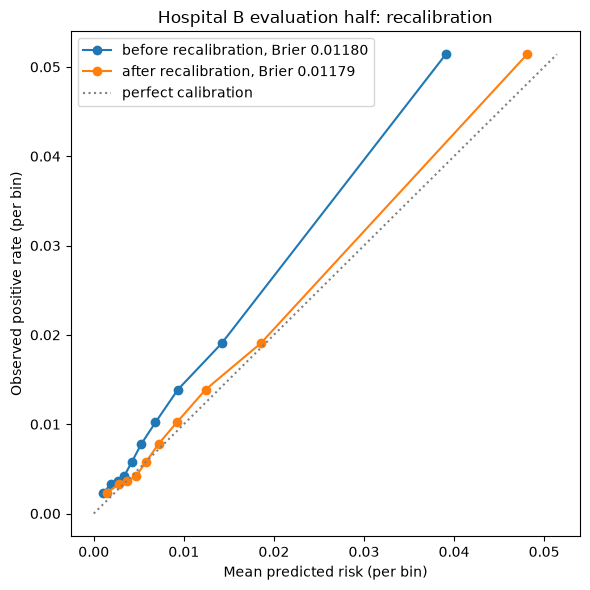

In [11]:
from sklearn.linear_model import LogisticRegression

def logit(p):
    p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

recal = LogisticRegression(C=1e6)          # essentially no regularization: just 2 numbers to fit
recal.fit(logit(b_cal["p"]), b_cal["y"])
print(f"Recalibration: slope {recal.coef_[0][0]:.3f}, intercept {recal.intercept_[0]:.3f}")

b_cal["p_recal"] = recal.predict_proba(logit(b_cal["p"]))[:, 1]
b_eval["p_recal"] = recal.predict_proba(logit(b_eval["p"]))[:, 1]

from sklearn.metrics import roc_auc_score
fig, ax = plt.subplots(figsize=(6, 6))
top = 0
for label, col in [("before recalibration", "p"), ("after recalibration", "p_recal")]:
    cal, brier = calibration(b_eval["y"], b_eval[col])
    ax.plot(cal["mean_predicted"], cal["observed_rate"], marker="o", label=f"{label}, Brier {brier:.5f}")
    top = max(top, cal["mean_predicted"].max(), cal["observed_rate"].max())
    print(f"{label}: mean predicted {b_eval[col].mean():.4f} vs observed {b_eval['y'].mean():.4f} | "
          f"AUROC {roc_auc_score(b_eval['y'], b_eval[col]):.3f}")
ax.plot([0, top], [0, top], linestyle=":", color="gray", label="perfect calibration")
ax.set_xlabel("Mean predicted risk (per bin)")
ax.set_ylabel("Observed positive rate (per bin)")
ax.set_title("Hospital B evaluation half: recalibration")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "recalibration_B.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
grid = np.round(np.arange(0.005, 0.10, 0.005), 3)
cal_table = threshold_table(b_cal.assign(p=b_cal["p_recal"]), grid)
meets_rule = cal_table[cal_table["early_sensitivity"] >= 0.5]
local_thr = float(meets_rule["threshold"].max()) if len(meets_rule) else float(grid.min())
print(f"Local threshold (chosen on calibration half, rule: ≥50% early sensitivity): {local_thr}")

comparison = pd.DataFrame([
    {"setting": "A's threshold 0.05, original scores", **alert_metrics(b_eval, THRESHOLD)},
    {"setting": f"local threshold {local_thr}, recalibrated scores",
     **alert_metrics(b_eval.assign(p=b_eval["p_recal"]), local_thr)},
]).drop(columns="threshold")
comparison.round(3)

Local threshold (chosen on calibration half, rule: ≥50% early sensitivity): 0.03


,setting,early_sensitivity,median_lead_h,alerts_per_100_patient_days,alert_ppv,nonseptic_patients_alerted
0,"A's threshold 0.05, original scores",0.247,5.0,12.590,0.110,0.067
1,"local threshold 0.03, recalibrated scores",0.516,7.0,41.959,0.077,0.213


## Findings (Parts B and C)
**Drift (A train vs B, top 15 SHAP features):** 3 features with PSI > 0.25, all reflecting measurement/workflow rather than physiology: PTT_last (PSI 0.95; missing 33% → 78%), FiO2_hrs_since (0.67; missing 42% → 71%, median 2 → 11 h), HospAdmTime (0.65; median −2.6 → −9.0 h). Physiological values (BUN, lactate, Resp, Temp, Age) similar (PSI < 0.1).
**Score shift:** mean log-odds B − A = −0.377 (~31% lower odds, consistent with ~26% underestimation). FiO2_hrs_since alone −0.240 (~64%); all FiO2 features −0.311 (~82%); HospAdmTime −0.072; PTT_last −0.057. Hypothesis confirmed: lower scores at B are driven mainly by less frequent FiO2 recording.
**Recalibration (logistic, fit on half of B, evaluated on the other half):** slope 0.960, intercept 0.102; mean predicted 0.0088 → 0.0114 vs observed 0.0121; AUROC unchanged (0.766); Brier essentially unchanged (0.01180 → 0.01179; insensitive at this prevalence).
**Local threshold:** 0.03 (rule: ≥50% early sensitivity, chosen on calibration half). Evaluation half: early sensitivity 25% → 52%, median lead 5 → 7 h, alerts 13 → 42 per 100 patient-days, PPV 11.0% → 7.7% (~13 alerts per true early warning vs ~8 at A), non-septic alerted 7% → 21%.
**Conclusion:** ranking mostly transfers; scale does not, because of site-specific measurement habits. Local recalibration and threshold selection restore A-level early sensitivity, at lower precision. Recovering precision would need retraining with B-like data or less site-dependent features.